# Các quyết định cần xác nhận và hồ sơ nghiệm thu bước 3
**Đồ án CV nâng cao · Nhóm A/B/C · 28/10/2026**

Notebook này làm rõ: phần kỹ thuật nào đã được kiểm bằng code, những lựa chọn nào cần bạn xác nhận, và những ca ảnh nào cần người duyệt riêng. Một lời đồng ý chính sách không được tính thành xác nhận danh tính của hàng nghìn ảnh.

Đã được giao quyền chủ động phần kỹ thuật và bắt đầu bước mới khi phù hợp. Vì vậy pilot preprocessing chỉ trên **validation DigiFace** được phép chạy song song; không cần đợi duyệt mọi ảnh mới kiểm tensor hoặc detector. Test và ROF/MFR2 vẫn ngoài tuning.

## 1. Đầu vào, cách chạy và phạm vi

Chạy sau notebook QA và protocol bằng **Restart Kernel → Run All**. Dữ liệu quyết định thật ở `input/`, chỉ được đọc; các template, hàng đợi và contact sheet trong `notebook_outputs/` là đầu ra. Không điền quyết định giả để làm bảng tiến độ trông hoàn thành.

Các ảnh gallery được mở để tạo tài liệu QA, không tính score nhận diện, không dùng ảnh thật hoặc test để tối ưu preprocessing. Raw không bị ghi. Việc xem được ba ảnh cùng nhãn cũng chưa phải nguồn xác minh danh tính độc lập.

In [1]:
from pathlib import Path
from datetime import datetime,timezone
import hashlib,json,math,os,time
import pandas as pd
import numpy as np
from PIL import Image,ImageOps,ImageDraw,ImageFont
from IPython.display import display,Markdown

def find_root():
    options=[]
    if os.environ.get('CV_PROJECT_ROOT'):options.append(Path(os.environ['CV_PROJECT_ROOT']))
    for p in [Path.cwd(),*Path.cwd().parents]:
        options += [p,p/'Đồ Án/Codex Works/DoAn_CV_NangCao',p/'Codex Works/DoAn_CV_NangCao']
    for p in options:
        if (p/'ban_giao_nhom/quyet_dinh_nhom/Cac_quyet_dinh_can_xac_nhan.ipynb').is_file():return p.resolve()
    raise FileNotFoundError('Mở trong cấu trúc dự án hoặc đặt CV_PROJECT_ROOT')

ROOT=find_root();HERE=ROOT/'ban_giao_nhom/quyet_dinh_nhom'
PRO=ROOT/'ban_giao_nhom/protocol';QA=ROOT/'ban_giao_nhom/qa'
OUT=HERE/'notebook_outputs';TAB=OUT/'tables';SHEETS=OUT/'contact_sheets';TEMPLATES=OUT/'templates'
for p in [OUT,TAB,SHEETS,TEMPLATES]:p.mkdir(parents=True,exist_ok=True)
START=time.perf_counter()
def sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for block in iter(lambda:f.read(2**20),b''):h.update(block)
    return h.hexdigest()
def save(d,name):d.to_csv(TAB/(name+'.csv'),index=False,encoding='utf-8-sig');return d
def jwrite(d,p):p.write_text(json.dumps(d,ensure_ascii=False,indent=2),encoding='utf-8')
def read(p):return pd.read_csv(p,dtype=str,keep_default_na=False)
def vn(x):return f'{int(x):,}'.replace(',','.')
inputs={
    'protocol':PRO/'notebook_outputs/protocol_draft.json',
    'internal_roles':PRO/'notebook_outputs/tables/05_image_roles_draft.csv',
    'rof_roles':PRO/'notebook_outputs/tables/07_rof_image_roles_draft.csv',
    'gallery_queue':PRO/'notebook_outputs/tables/07_gallery_review_queue.csv',
    'protocol_summary':PRO/'notebook_outputs/execution_summary.json',
    'qa_manifest':QA/'notebook_outputs/tables/16_QA_manifest_proposed.csv',
    'qa_page_map':QA/'notebook_outputs/tables/14_all_review_page_map.csv',
    'project_decisions':HERE/'input/project_decisions.csv',
    'gallery_review':HERE/'input/gallery_review.csv',
}
fingerprints=save(pd.DataFrame([{'key':k,'path':p.relative_to(ROOT).as_posix(),
                               'sha256':sha(p),'bytes':p.stat().st_size} for k,p in inputs.items()]),'01_input_fingerprints')
protocol=json.loads(inputs['protocol'].read_text(encoding='utf-8'))
execution=json.loads(inputs['protocol_summary'].read_text(encoding='utf-8'))
internal,rof,gallery,manifest=[read(inputs[k]) for k in ['internal_roles','rof_roles','gallery_queue','qa_manifest']]
assert execution['checks']=='PASS'
assert gallery.image_id.is_unique and gallery.role.eq('gallery').all()
assert set(gallery.image_id)==set(internal[internal.role.eq('gallery')].image_id)|set(rof[rof.role.eq('gallery')].image_id)
assert not protocol['frozen']
display(fingerprints[['key','bytes','sha256']])

,key,bytes,sha256
0,protocol,51796,6e471b0d29186648add229657a875f97fb98b597288ab3...
1,internal_roles,41694530,b230104ba43a8060c948cba3c06473256d535efc797493...
2,rof_roles,3573033,3540732b88c60d8842c454b9c84a44ece5f458f3e377b6...
3,gallery_queue,460103,26e39c7d767eac48760f6036d56e94f68077224b0e4f02...
4,protocol_summary,2466,69787b4ae2194e26d3d19ffefebdcbeedeaac869f50882...
5,qa_manifest,33783973,249cfd4c178e7fef4bd9665620a02b88d16469e8ed8820...
6,qa_page_map,33607,1a7f8534c8299f59270190a7c2342bbd1f05c869f2d031...
7,project_decisions,751,8afee02167381ef2684d1e6f395522b7e85b588f03e00f...
8,gallery_review,68,4b9789615078008d7d88d06b84fa0c56cd62a2f1c54094...


## 2. Các lựa chọn cần xác nhận trước khi chốt protocol chính thức

Các lựa chọn dưới đây đã có phương án khuyến nghị và danh sách ảnh cụ thể để kiểm. Bạn có thể trả lời ngay trong chat bằng mã P1–P5; trợ lý chỉ ghi lại khi có câu trả lời thật. Các default đang được dùng cho **bản nháp và pilot**, chưa phải lời duyệt của bạn.

Không cần xác nhận lại quyền chạy pilot kỹ thuật, tính hash, kiểm leakage hoặc giữ dữ liệu gốc: các việc đó nằm trong yêu cầu đã giao.

In [2]:
hold=int(manifest.qa_action_proposed.eq('hold_proposed').sum())
dup=int(manifest.qa_action_proposed.eq('duplicate_secondary_proposed').sum())
review=int(manifest.qa_action_proposed.eq('review_required').sum())
POLICIES=pd.DataFrame([
 {'decision_id':'P1','question':'Chính sách QA cho cohort chính thức',
  'recommended_option':'conservative_withhold',
  'recommendation':f'Tạm cách ly {vn(hold)} hold + {vn(dup)} bản trùng phụ trên danh sách; giữ {vn(review)} ca review kèm cờ. Không xóa raw hoặc sửa nhãn.',
  'alternative_option':'review_before_withhold','alternative':'Muốn duyệt thêm các ca bị giữ trước khi chốt cohort.',
  'evidence':'qa/notebook_outputs/tables/16_QA_manifest_proposed.csv',
  'does_not_confirm':'Không xác nhận từng nhãn người/box; không áp dụng delete hoặc relabel.'},
 {'decision_id':'P2','question':'Gallery DigiFace dùng ảnh nền hay bắt buộc ảnh rõ?',
  'recommended_option':'base_gallery_3',
  'recommendation':'Giữ 1.600/200/200 người; 100 known + 100 unknown mỗi val/test; gallery 3 ảnh nền/người. Ghi rõ synthetic_unannotated.',
  'alternative_option':'clear_gallery_review_first','alternative':'Chỉ phát hành gallery sau khi người duyệt xác nhận ảnh rõ; có thể cần phiên bản allocation mới.',
  'evidence':'protocol/notebook_outputs/tables/05_image_roles_draft.csv',
  'does_not_confirm':'Không gọi ảnh nền là clean và không coi gallery đã được xác minh danh tính.'},
 {'decision_id':'P3','question':'Vai trò dữ liệu ảnh thật và alias',
  'recommended_option':'external_test_only',
  'recommendation':'Giữ ROF/MFR2 ngoài tuning; alias chỉ làm guard, chưa merge người. MFR2 giữ 848 dòng nguồn và báo 843 cặp duy nhất không có hướng.',
  'alternative_option':'new_real_calibration_protocol','alternative':'Muốn dùng một phần ảnh thật cho calibration: cần chia identity/alias và tạo protocol mới trước khi chạy.',
  'evidence':'protocol/notebook_outputs/tables/07_rof_image_roles_draft.csv',
  'does_not_confirm':'Không khẳng định hai benchmark độc lập về người hoặc pretraining không có người trùng.'},
 {'decision_id':'P4','question':'Mục tiêu chọn ngưỡng và cách báo bất định',
  'recommended_option':'fpir_05_empirical',
  'recommendation':'Mục tiêu FPIR validation 5% theo point estimate; ngưỡng riêng từng model, chọn bằng validation; bootstrap theo identity.',
  'alternative_option':'revise_operating_point','alternative':'Muốn mục tiêu khác hoặc chọn theo upper confidence bound: chốt quy tắc mới trước score.',
  'evidence':'protocol/notebook_outputs/protocol_draft.json',
  'does_not_confirm':'Không bảo đảm FPIR thật ≤5%, không suy ngưỡng tổng hợp sang webcam ảnh thật.'},
 {'decision_id':'P5','question':'Cách chuẩn bị ảnh DigiFace cho encoder',
  'recommended_option':'direct_resize_digiface',
  'recommendation':'Resize thẳng ảnh DigiFace đã crop sẵn về 160×160 (cách A của pilot preprocessing); detector chỉ dùng cho webcam/ảnh toàn cảnh. Xem lại sau khi có kết quả B0 trên validation.',
  'alternative_option':'redetect_crop_digiface','alternative':'Chạy lại MTCNN rồi crop theo bbox (cách B); ảnh không tìm thấy mặt bị tính là thất bại.',
  'evidence':'preprocessing/notebook_outputs/tables/06_coverage_by_cohort_role.csv',
  'does_not_confirm':'Không chứng minh cách A nhận diện tốt hơn; chỉ chọn mặc định cho bước B0/evaluator.'},
])
save(POLICIES,'02_policy_choices')
display(POLICIES[['decision_id','question','recommendation','alternative']])

,decision_id,question,recommendation,alternative
0,P1,Chính sách QA cho cohort chính thức,Tạm cách ly 804 hold + 82 bản trùng phụ trên d...,Muốn duyệt thêm các ca bị giữ trước khi chốt c...
1,P2,Gallery DigiFace dùng ảnh nền hay bắt buộc ảnh...,Giữ 1.600/200/200 người; 100 known + 100 unkno...,Chỉ phát hành gallery sau khi người duyệt xác ...
2,P3,Vai trò dữ liệu ảnh thật và alias,Giữ ROF/MFR2 ngoài tuning; alias chỉ làm guard...,Muốn dùng một phần ảnh thật cho calibration: c...
3,P4,Mục tiêu chọn ngưỡng và cách báo bất định,Mục tiêu FPIR validation 5% theo point estimat...,Muốn mục tiêu khác hoặc chọn theo upper confid...
4,P5,Cách chuẩn bị ảnh DigiFace cho encoder,Resize thẳng ảnh DigiFace đã crop sẵn về 160×1...,Chạy lại MTCNN rồi crop theo bbox (cách B); ản...


## 3. Đọc quyết định thật: kiểm chặt và không ghi đè input

`project_decisions.csv`: một dòng/mỗi mã P1–P5, lựa chọn đúng mã, người quyết định, ngày ISO và lý do. `gallery_review.csv`: một dòng/ảnh gallery, quyết định, người duyệt, ngày và đường dẫn bằng chứng.

Các quyết định gallery được phép: `accept_base_gallery`, `clear_face_confirmed`, `reject_gallery`, `uncertain`. Chúng mô tả khả năng dùng ảnh/quan sát mặt rõ; không tự đặt `identity_verified_independently=True`. Muốn đổi nhãn/khôi phục crop đang bị giữ, dùng quy trình QA có bằng chứng và tạo protocol version mới.

In [3]:
def validate_human_inputs(policy_rows, image_rows):
    required_policy=['decision_id','chosen_option','reviewer','reviewed_at','reason']
    required_gallery=['image_id','decision','reviewer','reviewed_at','evidence_reference','notes']
    if list(policy_rows.columns)!=required_policy:raise ValueError('Sai schema project_decisions')
    if list(image_rows.columns)!=required_gallery:raise ValueError('Sai schema gallery_review')
    if not policy_rows.decision_id.is_unique or not image_rows.image_id.is_unique:raise ValueError('ID review trùng')
    allowed={r.decision_id:{r.recommended_option,r.alternative_option} for r in POLICIES.itertuples()}
    for r in policy_rows.itertuples():
        if r.decision_id not in allowed or r.chosen_option not in allowed[r.decision_id]:raise ValueError('Mã quyết định/lựa chọn lạ')
    if not image_rows.image_id.isin(gallery.image_id).all():raise ValueError('Ảnh review không thuộc gallery hiện hành')
    if not image_rows.decision.isin(['accept_base_gallery','clear_face_confirmed','reject_gallery','uncertain']).all():
        raise ValueError('Quyết định gallery lạ')
    for frame,fields in [(policy_rows,required_policy),(image_rows,required_gallery[:-1])]:
        if not frame[fields].apply(lambda c:c.str.strip().ne('')).all().all():raise ValueError('Thiếu trường bắt buộc')
        for d in frame.reviewed_at:datetime.fromisoformat(d.replace('Z','+00:00'))
    return policy_rows.copy(),image_rows.copy()

human_policy,human_gallery=validate_human_inputs(read(inputs['project_decisions']),read(inputs['gallery_review']))
decision_board=POLICIES.merge(human_policy,on='decision_id',how='left',validate='one_to_one').fillna('')
decision_board['status']=np.where(decision_board.chosen_option.eq(''),'awaiting_user_confirmation',
                               np.where(decision_board.chosen_option.eq(decision_board.recommended_option),'recommended_option_confirmed','alternative_requested'))
save(decision_board,'03_policy_decision_status')
gallery_status=gallery.merge(human_gallery,on='image_id',how='left',validate='one_to_one').fillna('')
gallery_status['human_review_status']=np.where(gallery_status.decision.eq(''),'pending',gallery_status.decision)
save(gallery_status,'03_gallery_review_status')
pd.DataFrame(columns=human_policy.columns).to_csv(TEMPLATES/'project_decisions_template.csv',index=False,encoding='utf-8-sig')
gallery_template=gallery[['image_id','source','canonical_identity','partition','path']].copy()
for col in ['decision','reviewer','reviewed_at','evidence_reference','notes']:gallery_template[col]=''
gallery_template.to_csv(TEMPLATES/'gallery_review_worksheet.csv',index=False,encoding='utf-8-sig')
display(decision_board[['decision_id','question','status','chosen_option']])
display(gallery_status.groupby(['source','partition','human_review_status']).size().rename('images').reset_index())

,decision_id,question,status,chosen_option
0,P1,Chính sách QA cho cohort chính thức,recommended_option_confirmed,conservative_withhold
1,P2,Gallery DigiFace dùng ảnh nền hay bắt buộc ảnh...,recommended_option_confirmed,base_gallery_3
2,P3,Vai trò dữ liệu ảnh thật và alias,recommended_option_confirmed,external_test_only
3,P4,Mục tiêu chọn ngưỡng và cách báo bất định,recommended_option_confirmed,fpir_05_empirical
4,P5,Cách chuẩn bị ảnh DigiFace cho encoder,recommended_option_confirmed,direct_resize_digiface


,source,partition,human_review_status,images
0,DigiFace,test,pending,300
1,DigiFace,val,pending,300
2,ROF,external_test_reserve,pending,432


### Tự kiểm luồng quyết định

Các fixture bên dưới chỉ nằm trong RAM, để kiểm input hợp lệ được giữ nguyên qua hai lượt và input sai bị chặn. Chúng không phải quyết định của thành viên, không được ghi vào CSV thật hoặc tính vào tiến độ duyệt.

In [4]:
fixture_policy=pd.DataFrame([['P1','conservative_withhold','TEST_FIXTURE','2026-10-28','memory_only']],columns=human_policy.columns)
fixture_gallery=pd.DataFrame([[gallery.image_id.iloc[0],'uncertain','TEST_FIXTURE','2026-10-28','memory_only','fixture']],columns=human_gallery.columns)
a,b=validate_human_inputs(fixture_policy,fixture_gallery)
aa,bb=validate_human_inputs(a,b)
pd.testing.assert_frame_equal(a,aa);pd.testing.assert_frame_equal(b,bb)
fixture_results=[{'case':'Hợp lệ + hai lượt giữ nguyên','passed':True}]
invalid=[]
p=fixture_policy.copy();p.loc[0,'chosen_option']='unknown';invalid.append(('Sai mã lựa chọn',p,fixture_gallery))
p=fixture_policy.copy();p.loc[0,'reviewer']='';invalid.append(('Thiếu người duyệt',p,fixture_gallery))
p=fixture_policy.copy();p.loc[0,'reviewed_at']='not-a-date';invalid.append(('Sai ngày ISO',p,fixture_gallery))
g=fixture_gallery.copy();g.loc[0,'image_id']='missing_image';invalid.append(('ID ảnh lạ',fixture_policy,g))
invalid.append(('Dòng trùng',pd.concat([fixture_policy,fixture_policy]),fixture_gallery))
for label,p,g in invalid:
    rejected=False
    try:validate_human_inputs(p,g)
    except (ValueError,KeyError):rejected=True
    assert rejected,label
    fixture_results.append({'case':label,'passed':rejected})
save(pd.DataFrame(fixture_results),'04_human_input_contract_tests')
display(pd.DataFrame(fixture_results))

,case,passed
0,Hợp lệ + hai lượt giữ nguyên,True
1,Sai mã lựa chọn,True
2,Thiếu người duyệt,True
3,Sai ngày ISO,True
4,ID ảnh lạ,True
5,Dòng trùng,True


## 4. Hàng đợi theo ảnh: ưu tiên và vị trí bằng chứng

P1 duyệt **chính sách tạm giữ**, không cần xem hết các crop đang tạm giữ mới chạy pilot DigiFace. Nếu muốn phục hồi những ảnh đó hoặc công bố nhãn đã xác minh, cần review từng ca bằng ảnh nguồn/box và nguồn tham chiếu phù hợp.

Các sheet QA cũ và log AI được giữ làm bằng chứng, không đổi nhãn “AI đã xem” thành “nhóm đã duyệt”. Bảng dưới nối từng ảnh bị cách ly với trang có sẵn khi map có image ID; ca không có map trực tiếp vẫn có đường dẫn raw/crop và lý do.

In [5]:
page_map=read(inputs['qa_page_map'])
mapped=page_map[page_map.image_id.ne('')].groupby('image_id').sheet.agg(lambda s:'|'.join(sorted(set(s)))).rename('existing_QA_sheets')
held=manifest[manifest.qa_action_proposed.isin(['hold_proposed','duplicate_secondary_proposed'])].copy()
held=held.merge(mapped,on='image_id',how='left',validate='one_to_one').fillna('')
held['review_purpose']='Only required to recover/relabel or verify these cases; not a prerequisite for VAL tensor pilot'
held['human_confirmed']=False
save(held,'05_withheld_case_review_queue')
reason_counts=save(held.assign(reason=held.qa_reasons.str.split('|')).explode('reason').groupby(
    ['qa_action_proposed','reason']).size().rename('images').reset_index(),'05_withheld_reasons')
display(reason_counts)
display(Markdown(f'Có **{vn(len(held))} ảnh bị cách ly** trong bản nháp; '
                 f'**{vn(held.existing_QA_sheets.ne("").sum())} ảnh** có map trực tiếp tới sheet QA cũ. '
                 'Một ảnh có thể có nhiều lý do; không cộng số đếm lý do thành số ảnh.'))

,qa_action_proposed,reason,images
0,duplicate_secondary_proposed,proposed_duplicate_secondary,82
1,duplicate_secondary_proposed,review_author_box_clipped,2
2,duplicate_secondary_proposed,review_detector_policy_failure,5
3,duplicate_secondary_proposed,review_near_pair_unresolved,1
4,duplicate_secondary_proposed,review_quality_tail_proxy,1
5,hold_proposed,hold_below_baseline_min_side20,14
6,hold_proposed,hold_confirmed_photo_cross_label,2
7,hold_proposed,hold_exact_pixel_cross_label,2
8,hold_proposed,hold_low_information_crop,18
9,hold_proposed,hold_manual_crop_or_subject_review,25


Có **886 ảnh bị cách ly** trong bản nháp; **94 ảnh** có map trực tiếp tới sheet QA cũ. Một ảnh có thể có nhiều lý do; không cộng số đếm lý do thành số ảnh.

## 5. Bộ ảnh gallery để duyệt — đủ mọi ứng viên hiện hành

Mỗi hàng là ba ảnh gallery của một nhãn nguồn. Nhãn trên ảnh lấy từ manifest, không phải kết quả nhận diện. Mọi ảnh được kiểm SHA-256 trước khi mở; chỉ resize bản hiển thị trong RAM. Không dùng score, detector hoặc độ sáng để chọn ảnh khác thay cho ứng viên hiện tại.

Toàn bộ trang được lưu kèm map image ID → sheet/vị trí và SHA trang. Notebook hiển thị vài trang đầu của từng nhóm; bạn có thể mở các trang khác từ bảng index. Hình ROF chỉ phục vụ QA gallery, không đưa vào preprocessing pilot hoặc lựa chọn mô hình.

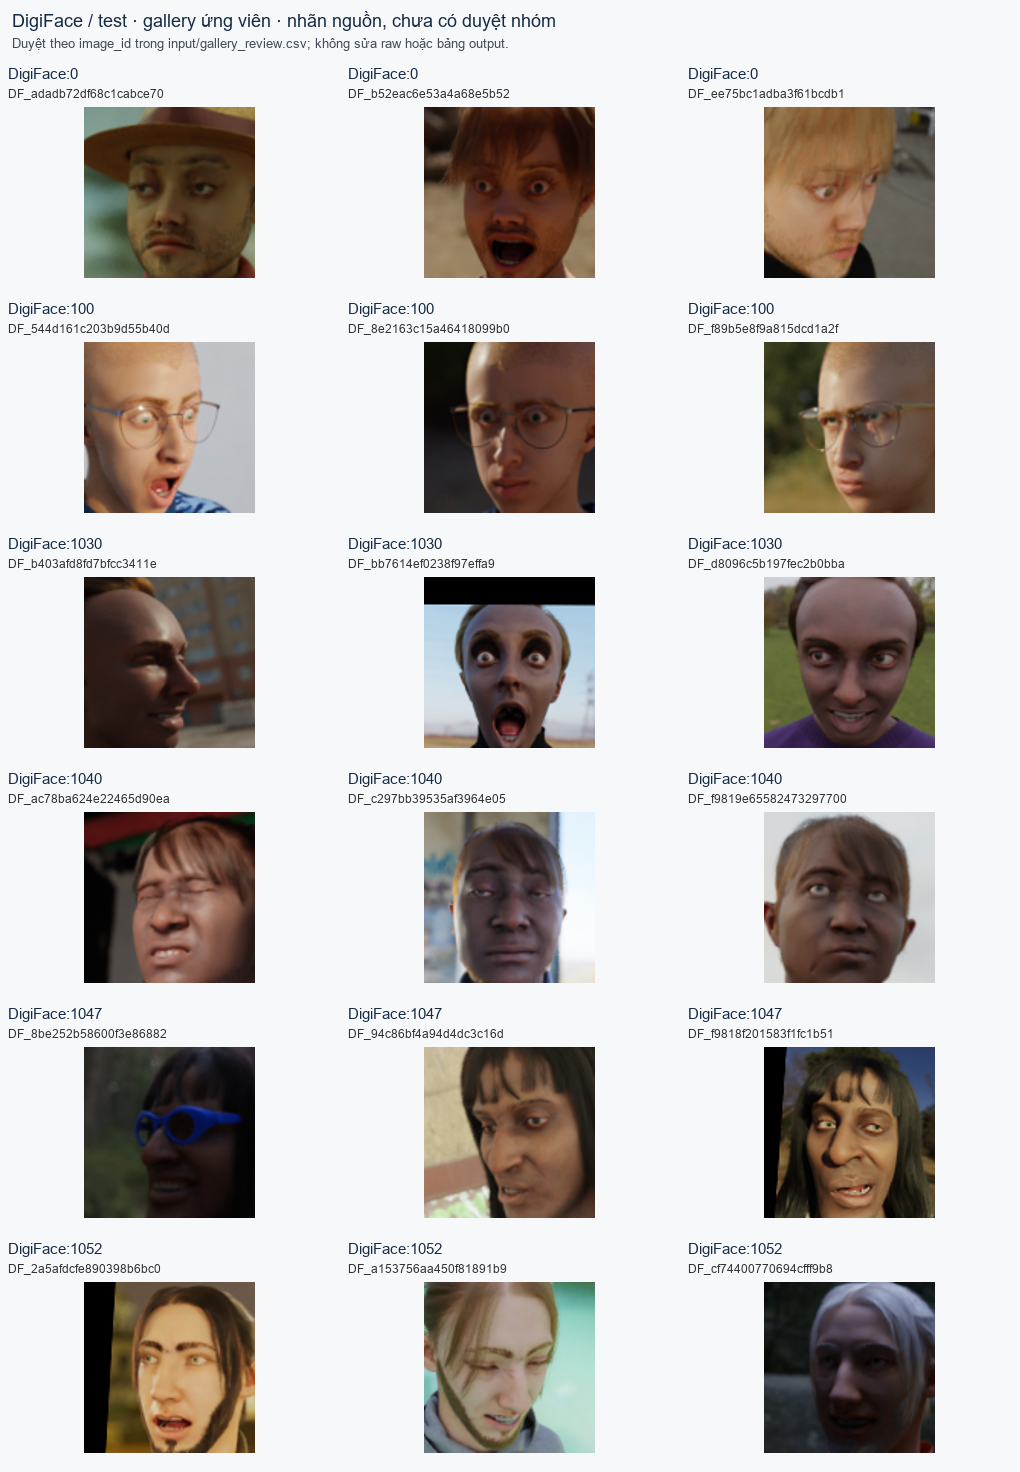

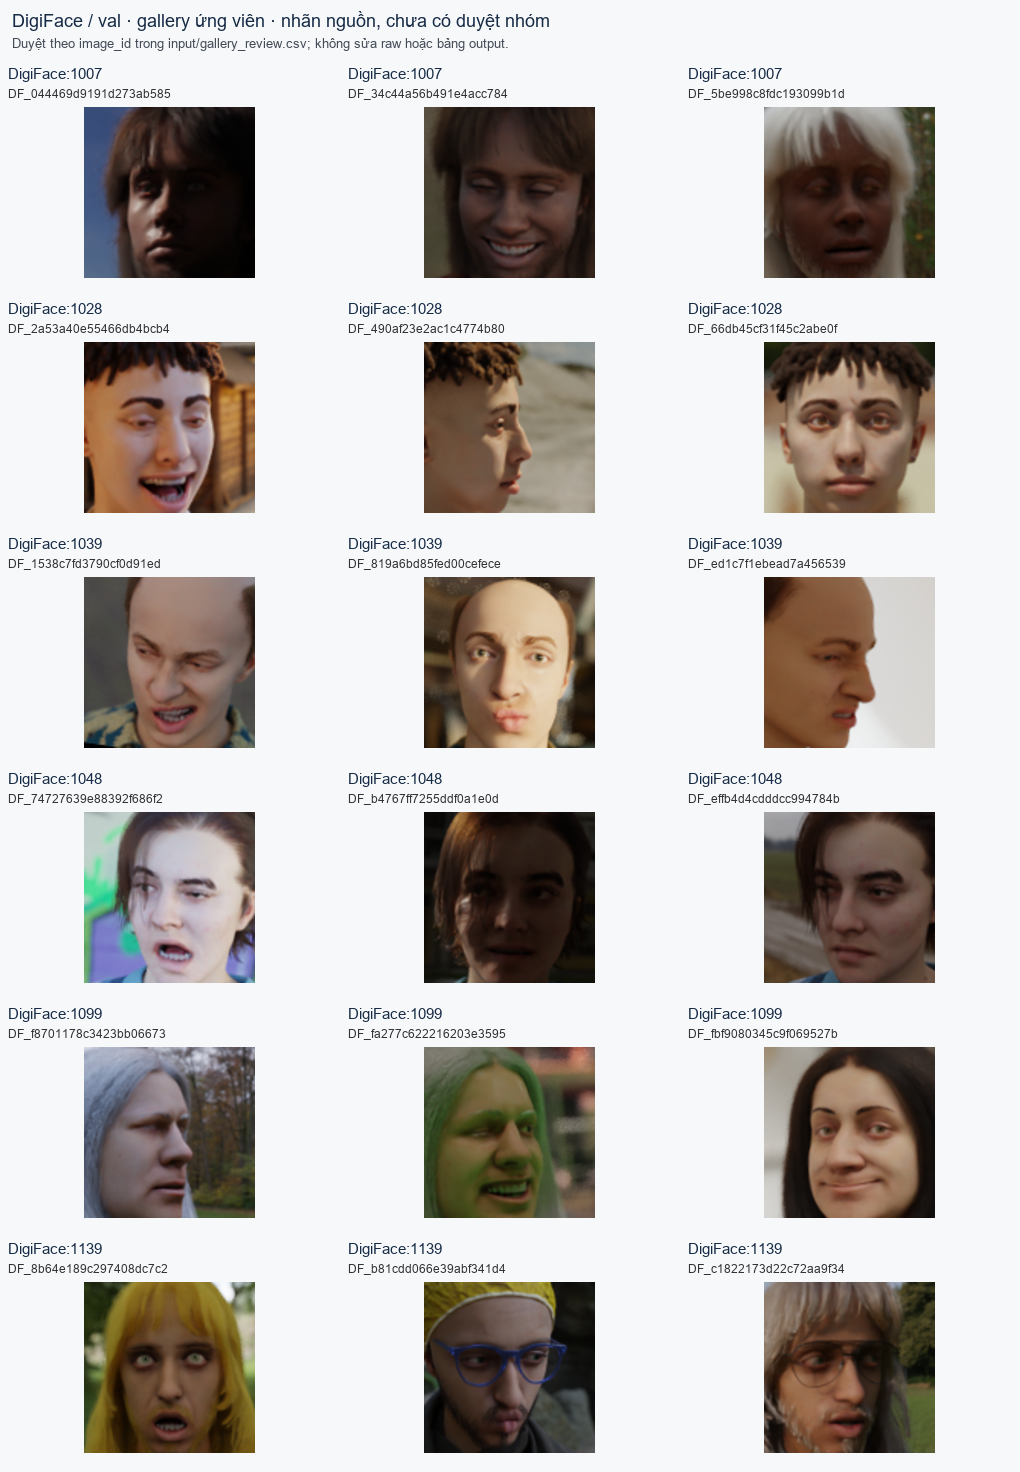

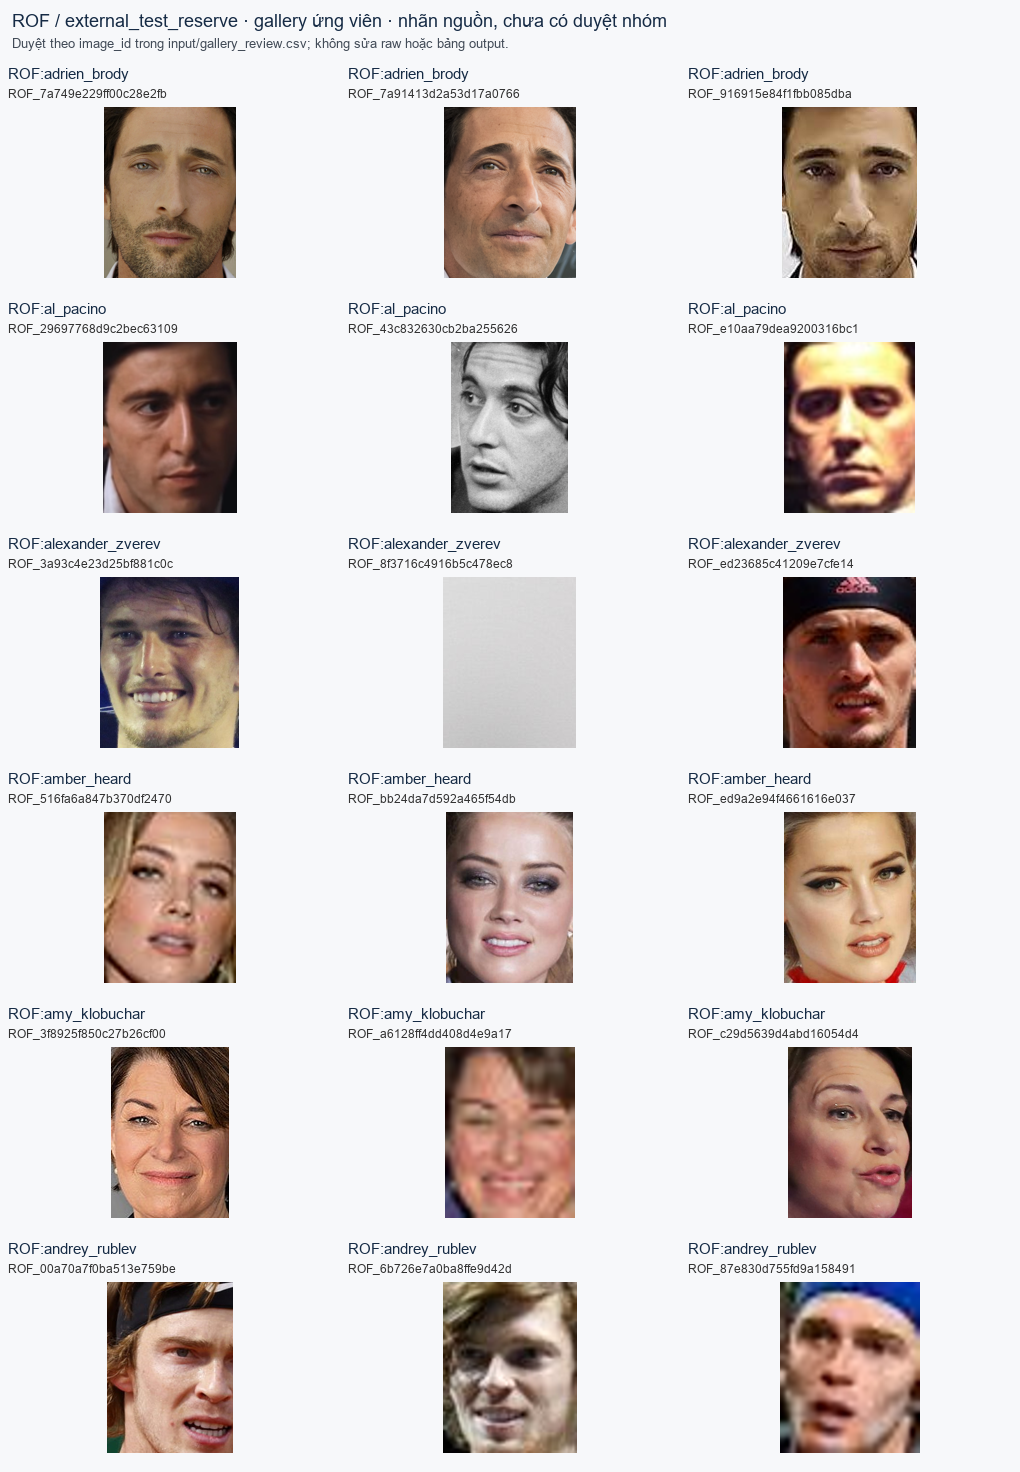

pages  images
source   partition                           
DigiFace test                      17     300
         val                       17     300
ROF      external_test_reserve     24     432

In [6]:
font_path=Path('C:/Windows/Fonts/arial.ttf')
def font(size):return ImageFont.truetype(str(font_path),size) if font_path.exists() else ImageFont.load_default()
maps=[];pages=[];verified=[]
for (source,partition),cohort in gallery.groupby(['source','partition'],sort=True):
    people=sorted(cohort.canonical_identity.unique())
    for start in range(0,len(people),6):
        block=people[start:start+6];cw,ch=340,235;head=62
        sheet=Image.new('RGB',(3*cw,len(block)*ch+head),'#f7f8fa');draw=ImageDraw.Draw(sheet)
        title=f'{source} / {partition} · gallery ứng viên · nhãn nguồn, chưa có duyệt nhóm'
        draw.text((12,10),title,font=font(18),fill='#162b45')
        draw.text((12,36),'Duyệt theo image_id trong input/gallery_review.csv; không sửa raw hoặc bảng output.',font=font(13),fill='#424b57')
        page_name=f'{source}_{partition}_{start//6+1:02d}.jpg'
        for row_index,identity in enumerate(block):
            person=cohort[cohort.canonical_identity.eq(identity)].sort_values('image_id')
            assert len(person)==3,'Gallery size đổi: cần phiên bản sheet mới'
            for col,row in enumerate(person.itertuples()):
                raw=ROOT/row.path
                assert sha(raw)==row.sha256,'Gallery đổi bytes: '+row.image_id
                with Image.open(raw) as im:
                    thumb=ImageOps.contain(ImageOps.exif_transpose(im).convert('RGB'),(cw-18,ch-64))
                x,y=col*cw,head+row_index*ch
                sheet.paste(thumb,(x+(cw-thumb.width)//2,y+45+(ch-64-thumb.height)//2))
                draw.text((x+8,y+3),row.canonical_identity,font=font(15),fill='#162b45')
                draw.text((x+8,y+25),row.image_id,font=font(12),fill='#333333')
                maps.append({'image_id':row.image_id,'canonical_identity':row.canonical_identity,'source':source,
                             'partition':partition,'sheet':page_name,'row':row_index+1,'column':col+1})
                verified.append(row.image_id)
        path=SHEETS/page_name;sheet.save(path,quality=88)
        pages.append({'source':source,'partition':partition,'sheet':page_name,'identities':len(block),
                      'images':len(block)*3,'sha256':sha(path)})
        if start==0:display(sheet)
page_index=save(pd.DataFrame(pages),'06_gallery_sheet_index')
page_map=save(pd.DataFrame(maps),'06_gallery_image_page_map')
assert set(verified)==set(gallery.image_id) and len(verified)==len(gallery)
assert page_map.image_id.is_unique and int(page_index.images.sum())==len(gallery)
display(page_index.groupby(['source','partition']).agg(pages=('sheet','size'),images=('images','sum')))

## 6. Khóa một phiên bản kỹ thuật, không giả phát hành semantic

Danh sách allocation có thể cố định ngay bằng hash để pilot và loader dùng đúng cùng ảnh. File snapshot dưới đây **chỉ tạo một lần**; Run All sau này phải khớp hoặc dừng yêu cầu tạo version mới. Nó không tự biến thành chứng nhận dữ liệu sạch hoặc quyền chạy test chính thức.

Các câu trả lời P1–P5 không nằm trong allocation snapshot vì không được phép ghi đè lịch sử khi có người duyệt sau này. Chúng có hash/input và trạng thái riêng. Nếu lựa chọn mới làm đổi cohort/gallery, phải tạo snapshot version mới thay vì sửa lén bản đã khóa.

In [7]:
SNAPSHOT_VERSION='stage3_allocation_20261028_v1'
snapshot_dir=HERE/'technical_snapshots';snapshot_dir.mkdir(exist_ok=True)
allocation_snapshot={
 'version':SNAPSHOT_VERSION,'technical_allocation_frozen':True,
 'official_dataset_release':False,'independent_identity_verification_claimed':False,
 'protocol_version':protocol['version'],
 'allocations':{k:{'path':inputs[k].relative_to(ROOT).as_posix(),'sha256':sha(inputs[k])}
                for k in ['internal_roles','rof_roles','gallery_queue']},
 'internal_images':len(internal),'rof_images':len(rof),'gallery_candidates':len(gallery),
 'pilot_scope':'DigiFace validation only; no recognition; raw read only',
}
snapshot_path=snapshot_dir/(SNAPSHOT_VERSION+'.json')
if snapshot_path.exists():
    assert json.loads(snapshot_path.read_text(encoding='utf-8'))==allocation_snapshot, 'Allocation đổi: tạo snapshot version mới, không ghi đè'
else:jwrite(allocation_snapshot,snapshot_path)
assert json.loads(snapshot_path.read_text(encoding='utf-8'))==allocation_snapshot
save(pd.DataFrame([{'scope':'Technical allocation/schema/hash','state':'FROZEN_VERSIONED'},
                  {'scope':'VAL preprocessing pilot','state':'AUTHORIZED_BY_CURRENT_USER'},
                  {'scope':'Policy P1–P5 confirmations','state':f'{len(human_policy)}/{len(POLICIES)} responses recorded'},
                  {'scope':'Gallery content review','state':f'{len(human_gallery)}/{len(gallery)} responses recorded'},
                  {'scope':'Official semantic dataset/test release','state':'NOT CLAIMED'}]),'07_readiness_levels')
display(pd.read_csv(TAB/'07_readiness_levels.csv'))

,scope,state
0,Technical allocation/schema/hash,FROZEN_VERSIONED
1,VAL preprocessing pilot,AUTHORIZED_BY_CURRENT_USER
2,Policy P1–P5 confirmations,5/5 responses recorded
3,Gallery content review,0/1032 responses recorded
4,Official semantic dataset/test release,NOT CLAIMED


## 7. Nghiệm thu Notebook này và cách trả lời

Câu trả lời P1–P5 được ghi vào `input/project_decisions.csv` (một dòng mỗi mã, có người quyết định, ngày và lý do). Muốn đổi lựa chọn thì sửa dòng tương ứng rồi Run All; nếu lựa chọn mới làm đổi cohort/gallery thì phải tạo snapshot allocation version mới.

Nếu muốn duyệt ảnh, xem `06_gallery_sheet_index.csv`, tìm ảnh trong `06_gallery_image_page_map.csv`; nhập các dòng thật vào `input/gallery_review.csv` theo schema, không sửa bảng output. Worksheet đầy đủ chỉ hỗ trợ tra cứu; file input có schema hẹp được kiểm để tránh trộn cột metadata vào quyết định.

Không cần có câu trả lời của bạn mới tính được tensor pilot. Các phần chưa được xác nhận tiếp tục hiện `pending` trong báo cáo, và không biến thành kết quả thực nghiệm nhận diện.

In [8]:
for r in fingerprints.itertuples():assert sha(ROOT/r.path)==r.sha256,'Input đổi trong lúc chạy: '+r.key
source_nb=json.loads((HERE/'Cac_quyet_dinh_can_xac_nhan.ipynb').read_text(encoding='utf-8'))
source_sha=hashlib.sha256(json.dumps([(c['cell_type'],''.join(c['source'])) for c in source_nb['cells']],ensure_ascii=False).encode()).hexdigest()
artifacts=save(pd.DataFrame([{'path':p.relative_to(HERE).as_posix(),'sha256':sha(p),'bytes':p.stat().st_size}
    for p in sorted(OUT.rglob('*')) if p.is_file() and p.name not in ['08_artifact_hashes.csv','execution_summary.json']]),'08_artifact_hashes')
summary={'checks':'PASS','allocation_snapshot_sha256':sha(snapshot_path),
         'technical_allocation_frozen':True,'official_dataset_release':False,
         'policy_responses_recorded':len(human_policy),'gallery_responses_recorded':len(human_gallery),
         'gallery_images_hash_verified':len(verified),'gallery_pages':len(page_index),
         'input_contract_tests':len(fixture_results),'human_input_written_by_notebook':False,
         'identity_verified_independently_set':False,'raw_modified':False,
         'notebook_source_sha256':source_sha,'executed_at_utc':datetime.now(timezone.utc).isoformat(),
         'elapsed_seconds':round(time.perf_counter()-START,3)}
jwrite(summary,OUT/'execution_summary.json')
display(Markdown(f"""**Kết quả:** allocation kỹ thuật có snapshot và kiểm hash; **{vn(len(gallery))} ảnh gallery** đã tạo thành **{len(page_index)} trang** để duyệt.

Có **{len(human_policy)}/4 câu trả lời chính sách** và **{len(human_gallery)} dòng review ảnh** thật được ghi nhận. Bản gốc và input con người giữ nguyên. Phần tiếp theo được phép là pilot preprocessing trên validation DigiFace; các ca semantic chưa duyệt vẫn pending."""))

**Kết quả:** allocation kỹ thuật có snapshot và kiểm hash; **1.032 ảnh gallery** đã tạo thành **58 trang** để duyệt.

Có **5/4 câu trả lời chính sách** và **0 dòng review ảnh** thật được ghi nhận. Bản gốc và input con người giữ nguyên. Phần tiếp theo được phép là pilot preprocessing trên validation DigiFace; các ca semantic chưa duyệt vẫn pending.